In [39]:
import os

os.environ["OMP_NUM_THREADS"] = "1"

In [40]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [41]:
iris = load_iris()

X = iris.data
y = iris.target

In [42]:
# scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<Axes: >

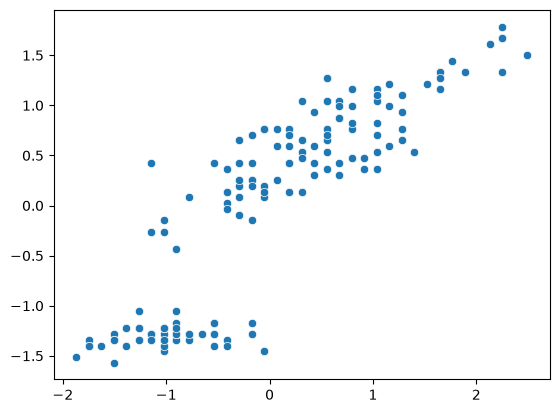

In [43]:
# visualize
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 2])

Text(0.5, 1.0, 'Dendrogram for hierarchical clustering')

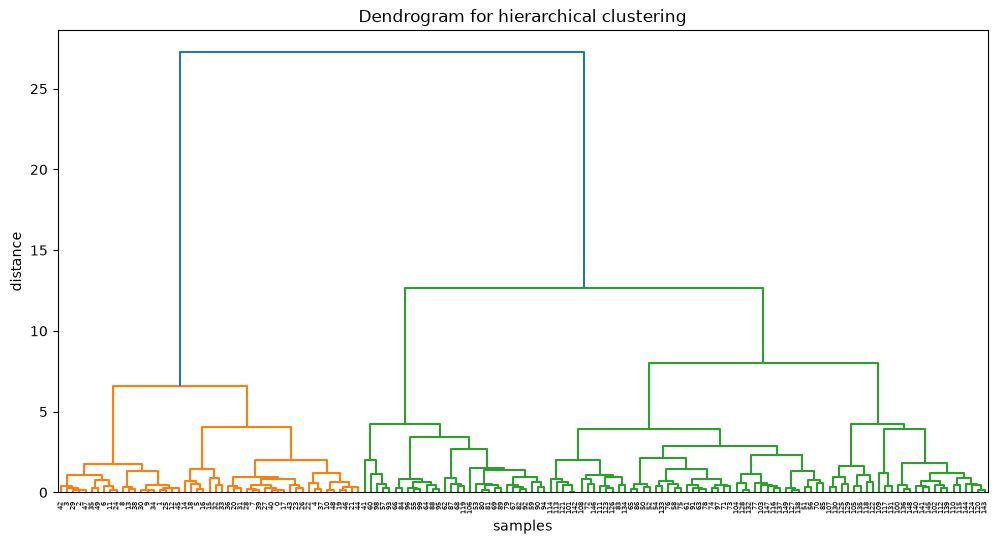

In [44]:
from scipy.cluster.hierarchy import linkage, dendrogram

# linkage matrix
Z = linkage(X_scaled, method="ward")

# Plot
plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.xlabel("samples")
plt.ylabel("distance")
plt.title("Dendrogram for hierarchical clustering")

# AgglomerativeClustering

In [45]:
# Clustering
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=3)
labels = agg.fit_predict(X_scaled)

<Axes: >

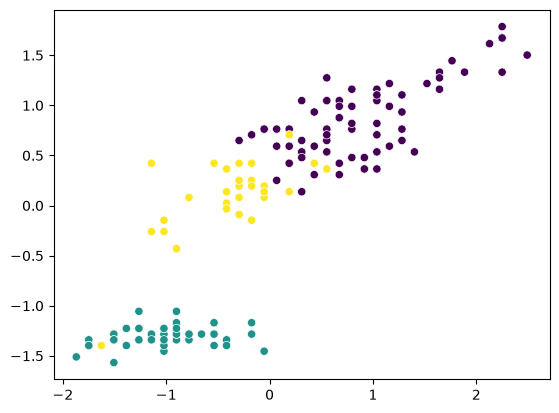

In [46]:
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 2], c=labels)

In [47]:
from sklearn.metrics import adjusted_rand_score

score = adjusted_rand_score(y, labels)

print("ARI Score:", score)

ARI Score: 0.6153229932145449


# DivisiveClustering

In [48]:
from sklearn.cluster import BisectingKMeans

div = BisectingKMeans(
    n_clusters=3,
    random_state=42
)

labels = div.fit_predict(X_scaled)

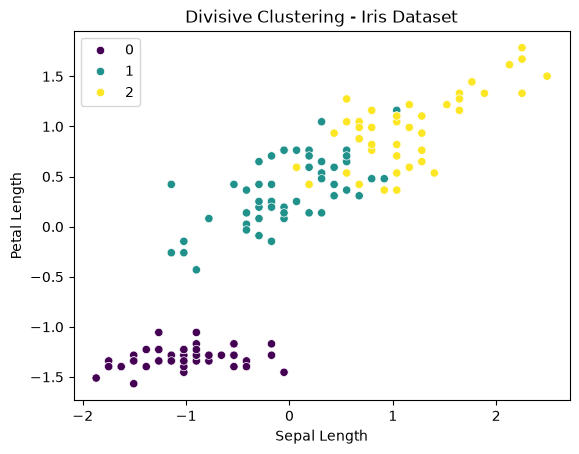

In [49]:
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 2],
    hue=labels,
    palette="viridis"
)

plt.title("Divisive Clustering - Iris Dataset")
plt.xlabel("Sepal Length")
plt.ylabel("Petal Length")

plt.show()

In [50]:
from sklearn.metrics import adjusted_rand_score

score = adjusted_rand_score(y, labels)

print("ARI Score:", score)

ARI Score: 0.5923326221845838
